In [ ]:
import cv2 as cv
import matplotlib.pyplot as plt
from ultralytics import YOLO
import torch
import numpy as np
# check de uso de GPU

cuda = torch.cuda.is_available()
if cuda:
    print("GPU reconhecida")
    print("Carregando modelo YOLO")
    model = YOLO("yolov8n.pt")
else:
    print("O programas está usando a CPU")


GPU reconhecida
Carregando modelo YOLO


In [ ]:
#results = model("group-of-people-18.jpg")
results = model.train(data="data.yaml", epochs=70, imgsz=640);


WARNING 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/8447) d:\Programa\video3.mp4: 736x1280 1 fogo, 195.9ms
video 1/1 (frame 2/8447) d:\Programa\video3.mp4: 736x1280 1 fogo, 112.3ms
video 1/1 (frame 3/8447) d:\Programa\video3.mp4: 736x1280 1 fogo, 16.7ms
video 1/1 (frame 4/8447) d:\Programa\video3.mp4: 736x1280 1 fogo, 15.7ms
video 1/1 (frame 5/8447) d:\Programa\video3.mp4: 736x1280 1 fogo, 15.7ms
video 1/1 (frame 6/8447) d:\Programa\video3.mp4: 736x1280 1 fogo, 15.6ms
video 1/1 (frame 7/844

[]


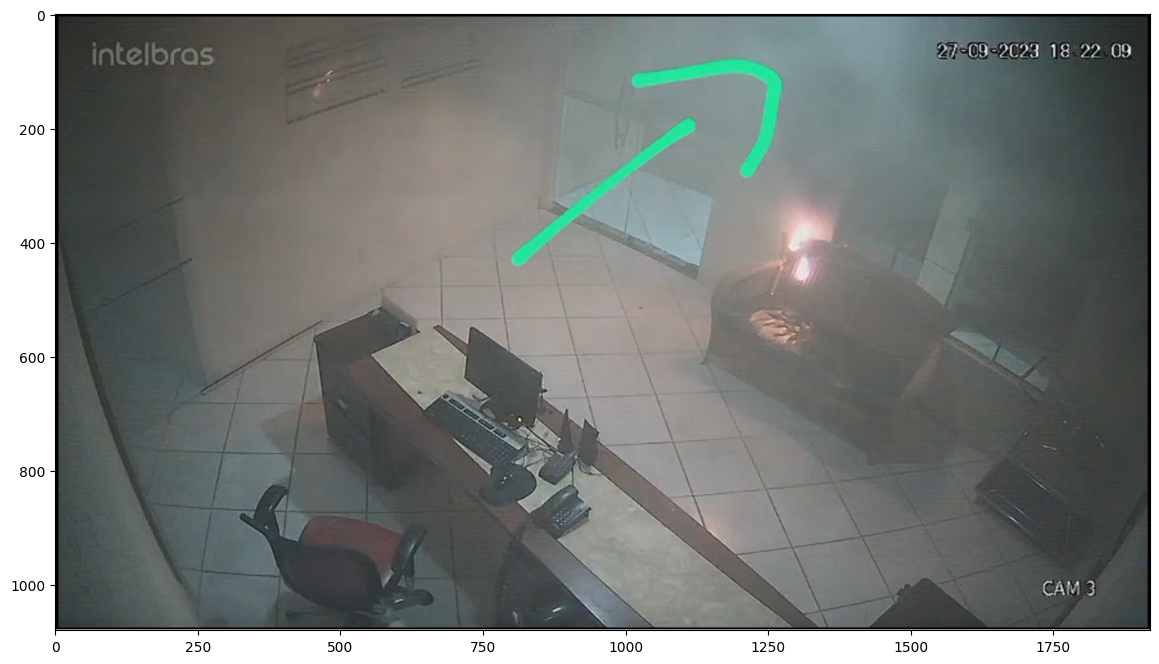

In [121]:
img = cv.imread(image)
def show_image(img):
    fig, ax = plt.subplots(1, figsize=(16, 8))
    plt.imshow(cv.cvtColor(img,cv.COLOR_BGR2RGB))
    for result in results:
        xyxy = result.boxes.xyxy.cpu().numpy()
        confs = result.boxes.conf.cpu().numpy()
        clss = result.boxes.cls.int().cpu().numpy()
        print(clss)
    for i in range(len(xyxy)):
        xmin,ymin,xmax,ymax = xyxy[i]
        w = xmax - xmin
        h = ymax - ymin
        print(xmin)
        rect = plt.Rectangle(
            (xmin, ymin), w, h,
            linewidth=2,edgecolor="red", facecolor="none"
        )
        ax.add_patch(rect)
    plt.show()

show_image(img)